# Kindly Install All Dependencies Using 'PIP'

In [1]:
!pip install combinations

  Preparing metadata (setup.py) ... done
  Created wheel for combinations: filename=combinations-0.1-py3-none-any.whl size=1670 sha256=2dda746e3bd856c9b12de23fafbd5c45e96e549a5ccf2faeb6744ce1ae0d3a00
  Stored in directory: /root/.cache/pip/wheels/15/82/72/36a8a251dd08684223769b9f56db15aea07e925a62e7f1e0cc
Successfully built combinations


#Procedure for running code

---

The code must run seperately for testing the model for 1m (test_D1), 3m (test_d2) and 5m (test_D3) seperately.



#Resources utilized

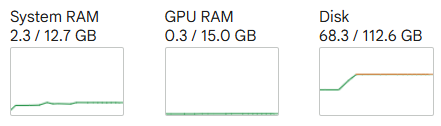

In [2]:
# ==============================================================================
# RESEARCH PIPELINE: SOUND SOURCE LOCALIZATION (CONVENTIONAL vs. ML FFNN)
# ==============================================================================

import os
import re
import csv
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
from itertools import combinations

# --- SECTION 1: DATASET INGESTION FROM GOOGLE DRIVE ---
print("--- Step 1: Downloading Dataset from Google Drive ---")

# File ID extracted from your shared Google Drive link
FILE_ID = "1fD4IcF4GsSFawr0javuxYR9xazRhpqLo"
ZIP_NAME = "FOR_SSL_Dataset_With_Code.zip"
EXTRACT_DIR = "./dataset"

# Download using gdown
if not os.path.exists(ZIP_NAME) and not os.path.exists(EXTRACT_DIR):
    print("Downloading dataset from Google Drive...")
    !gdown {FILE_ID} -O {ZIP_NAME}
    print("Extracting zip file...")
    !unzip -q {ZIP_NAME} -d {EXTRACT_DIR}
    print("Extraction complete.")
else:
    print("Dataset already downloaded and extracted.")

# --- SECTION 2: AUTOMATIC PATH RESOLUTION ---
def locate_split_folder(base_path, target_name):
    """Recursively locates subfolders across nested extraction paths."""
    matches = glob.glob(f"{base_path}/**/{target_name}", recursive=True)
    if not matches:
        raise FileNotFoundError(f"[Error] Could not locate folder '{target_name}' inside '{base_path}'")
    return matches[0]

TRAIN_DIR = locate_split_folder(EXTRACT_DIR, "train")
VAL_DIR = locate_split_folder(EXTRACT_DIR, "val")
TEST_DIR = locate_split_folder(EXTRACT_DIR, "test_D3")
RESULTS_DIR = "./results"

os.makedirs(RESULTS_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nResolved Paths:")
print(f" -> Train Directory : {TRAIN_DIR}")
print(f" -> Val Directory   : {VAL_DIR}")
print(f" -> Test Directory  : {TEST_DIR}")
print(f" -> Device          : {device}")

# --- SECTION 3: CONVENTIONAL TDOA GCC-PHAT METHOD ---
print("\n--- Step 3: Running Conventional GCC-PHAT Algorithm ---")

index_to_angle = [0, 45, 90, 135, 180, 225, 270, 315]

# Theoretical TDOA reference signature matrix
gccphatmat = torch.FloatTensor([
    [-0.045, -0.045,  0.000,  0.000,  0.045,  0.045],
    [-0.045, -0.064, -0.045, -0.045,  0.000,  0.045],
    [ 0.000, -0.045, -0.045, -0.045, -0.045,  0.000],
    [ 0.045,  0.000, -0.045, -0.045, -0.064, -0.045],
    [ 0.045,  0.045,  0.000,  0.000, -0.045, -0.045],
    [ 0.045,  0.064,  0.045,  0.045,  0.000, -0.045],
    [ 0.000,  0.045,  0.045,  0.045,  0.045,  0.000],
    [-0.045,  0.000,  0.045,  0.045,  0.064,  0.045]
]).to(device)

def torch_gcc_phat_all_pairs(data, fs):
    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)
    ch_idx_a, ch_idx_b = zip(*combinations(range(n_channels), 2))
    ch_idx_a, ch_idx_b = torch.tensor(ch_idx_a), torch.tensor(ch_idx_b)
    SIG_A, SIG_B = signals_fft[ch_idx_a], signals_fft[ch_idx_b]
    R = SIG_A * torch.conj(SIG_B)
    phi = R / (torch.abs(R) + 1e-15)
    cc = torch.fft.irfft(phi, n=n_fft)
    max_shift = n_fft // 2
    cc_shifted = torch.cat((cc[:, -max_shift:], cc[:, :max_shift]), dim=-1)
    argmax_idx = torch.argmax(torch.abs(cc_shifted), dim=-1)
    shifts = argmax_idx - max_shift
    return ch_idx_a, ch_idx_b, (shifts.float() / fs)

def extract_angle_from_filename(filename):
    match = re.search(r'@(\d+)&', filename)
    return int(match.group(1)) if match else None

target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
conv_total_files = 0
conv_correct_predictions = 0

conv_test_files = glob.glob(os.path.join(TEST_DIR, "*.wav"))

for file_path in conv_test_files:
    fname = os.path.basename(file_path)
    ground_truth = extract_angle_from_filename(fname)
    if ground_truth is None: continue

    try:
        fs, data_np = wav.read(file_path)
        data = torch.from_numpy(data_np).float().to(device)
        if data.shape[0] < data.shape[1]: data = data.T

        idx_a, idx_b, tdoas = torch_gcc_phat_all_pairs(data, fs=fs)
        pair_map = {(int(a), int(b)): t for a, b, t in zip(idx_a, idx_b, tdoas)}
        current_tdoas = torch.tensor([pair_map.get(p, 0.0) for p in target_pairs]).to(device)

        tdoa_signs = torch.sign(current_tdoas)
        distances = torch.linalg.vector_norm(gccphatmat / 343 - tdoa_signs, dim=1)
        matched_index = torch.argmin(distances).item()
        predicted_angle = index_to_angle[matched_index]

        conv_total_files += 1
        if predicted_angle == ground_truth:
            conv_correct_predictions += 1
    except Exception:
        continue

conv_accuracy = (conv_correct_predictions / conv_total_files * 100) if conv_total_files > 0 else 0
print(f"Conventional GCC-PHAT Accuracy: {conv_accuracy:.2f}% ({conv_correct_predictions}/{conv_total_files} correct)")

# --- SECTION 4: MACHINE LEARNING (FFNN) TDOA METHOD ---
print("\n--- Step 4: Training Machine Learning (FFNN) Model ---")

class TDOAClassifier(nn.Module):
    def __init__(self):
        super(TDOAClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 8)
        )

    def forward(self, x):
        return self.network(x)

def get_tdoa_vector(file_path):
    fs, data = wav.read(file_path)
    data = torch.from_numpy(data).float()
    if data.shape[0] < data.shape[1]: data = data.T

    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)

    target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
    tdoas = []
    for (a, b) in target_pairs:
        R = signals_fft[a] * torch.conj(signals_fft[b])
        phi = R / (torch.abs(R) + 1e-15)
        cc = torch.fft.irfft(phi, n=n_fft)
        max_shift = n_fft // 2
        cc_shifted = torch.cat((cc[-max_shift:], cc[:max_shift]))
        shift = torch.argmax(torch.abs(cc_shifted)) - max_shift
        tdoas.append((shift.float() / fs) * 1000)

    return torch.stack(tdoas)

class AngleDataset(Dataset):
    def __init__(self, folder_path):
        self.data = []
        self.labels = []
        self.angle_to_idx = {0:0, 45:1, 90:2, 135:3, 180:4, 225:5, 270:6, 315:7}

        wav_files = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
        print(f"Processing '{folder_path}' ({len(wav_files)} files found)...")

        for fname in wav_files:
            match = re.search(r'@(\d+)&', fname)
            if match:
                angle = int(match.group(1))
                if angle in self.angle_to_idx:
                    v = get_tdoa_vector(os.path.join(folder_path, fname))
                    self.data.append(v)
                    self.labels.append(self.angle_to_idx[angle])

        if len(self.data) == 0:
            raise ValueError(f"0 valid samples loaded from {folder_path}. Check file tags!")

    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.data[i], self.labels[i]

train_set = AngleDataset(TRAIN_DIR)
val_set = AngleDataset(VAL_DIR)
test_set = AngleDataset(TEST_DIR)

train_loader = DataLoader(train_set, batch_size=min(8, len(train_set)), shuffle=True)
val_loader = DataLoader(val_set, batch_size=min(8, len(val_set)), shuffle=False)
test_loader = DataLoader(test_set, batch_size=min(8, len(test_set)), shuffle=False)

model = TDOAClassifier().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.00001)
criterion = nn.CrossEntropyLoss()

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("\nExecuting Training Loop (1000 Epochs)...")
for epoch in range(1000):
    model.train()
    total_train_loss, train_correct = 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == y).sum().item()

    train_loss = total_train_loss / len(train_loader)
    train_acc = (train_correct / len(train_set) * 100)

    model.eval()
    total_val_loss, val_correct = 0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            total_val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == y).sum().item()

    val_loss = total_val_loss / len(val_loader)
    val_acc = (val_correct / len(val_set) * 100)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:05d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

# Evaluate ML Test Set
model.eval()
ml_test_correct = 0
with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        preds = torch.argmax(model(X), dim=1)
        ml_test_correct += (preds == y).sum().item()

ml_accuracy = (ml_test_correct / len(test_set) * 100)

# --- SECTION 5: EXPORT HIGH-RESOLUTION FIGURES ---
print("\n--- Step 5: Saving Figures (.eps, .png, .tif, .jpg, .jpeg, .tiff) ---")

epochs_range = range(1, len(history['train_loss']) + 1)
formats = ['eps', 'png', 'tif', 'jpg', 'jpeg', 'tiff']

# 1. Loss Figure
plt.figure(1, figsize=(8, 5))
plt.plot(epochs_range, history['train_loss'], label='Training Loss', color='blue', linewidth=1.5)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='orange', linewidth=1.5)
plt.title('Training and Validation Loss (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_loss_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# 2. Accuracy Figure
plt.figure(2, figsize=(8, 5))
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', color='green', linewidth=1.5)
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='red', linewidth=1.5)
plt.title('Training and Validation Accuracy (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_accuracy_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# --- SUMMARY REPORT ---
print("\n" + "="*50)
print("             BENCHMARK RESULTS")
print("="*50)
print(f"1. Conventional GCC-PHAT Accuracy : {conv_accuracy:.2f}%")
print(f"2. ML (FFNN) Test Accuracy       : {ml_accuracy:.2f}%")
print("="*50)
print(f"Figures exported to '{RESULTS_DIR}' directory.")

--- Step 1: Downloading Dataset from Google Drive ---
Downloading...
From (original): https://drive.google.com/uc?id=1fD4IcF4GsSFawr0javuxYR9xazRhpqLo
From (redirected): https://drive.google.com/uc?id=1fD4IcF4GsSFawr0javuxYR9xazRhpqLo&confirm=t&uuid=4935e10a-8f70-4d67-9398-8228d371c17c
To: /content/FOR_SSL_Dataset_With_Code.zip
100% 11.2G/11.2G [02:22<00:00, 78.8MB/s]
Extracting zip file...
Extraction complete.

Resolved Paths:
 -> Train Directory : ./dataset/train
 -> Val Directory   : ./dataset/val
 -> Test Directory  : ./dataset/test_D3
 -> Device          : cuda

--- Step 3: Running Conventional GCC-PHAT Algorithm ---
Conventional GCC-PHAT Accuracy: 56.03% (330/589 correct)

--- Step 4: Training Machine Learning (FFNN) Model ---
Processing './dataset/train' (8630 files found)...
Processing './dataset/val' (1837 files found)...
Processing './dataset/test_D3' (589 files found)...

Executing Training Loop (1000 Epochs)...
Epoch 00001 | Train Loss: 2.0842 | Train Acc: 9.41% | Val Loss:


             BENCHMARK RESULTS
1. Conventional GCC-PHAT Accuracy : 56.03%
2. ML (FFNN) Test Accuracy       : 62.99%
Figures exported to './results' directory.


In [3]:
# ==============================================================================
# RESEARCH PIPELINE: SOUND SOURCE LOCALIZATION (CONVENTIONAL vs. ML FFNN)
# ==============================================================================

import os
import re
import csv
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
from itertools import combinations

# --- SECTION 1: DATASET INGESTION FROM GOOGLE DRIVE ---
print("--- Step 1: Downloading Dataset from Google Drive ---")

# File ID extracted from your shared Google Drive link
FILE_ID = "1fD4IcF4GsSFawr0javuxYR9xazRhpqLo"
ZIP_NAME = "FOR_SSL_Dataset_With_Code.zip"
EXTRACT_DIR = "./dataset"

# Download using gdown
if not os.path.exists(ZIP_NAME) and not os.path.exists(EXTRACT_DIR):
    print("Downloading dataset from Google Drive...")
    !gdown {FILE_ID} -O {ZIP_NAME}
    print("Extracting zip file...")
    !unzip -q {ZIP_NAME} -d {EXTRACT_DIR}
    print("Extraction complete.")
else:
    print("Dataset already downloaded and extracted.")

# --- SECTION 2: AUTOMATIC PATH RESOLUTION ---
def locate_split_folder(base_path, target_name):
    """Recursively locates subfolders across nested extraction paths."""
    matches = glob.glob(f"{base_path}/**/{target_name}", recursive=True)
    if not matches:
        raise FileNotFoundError(f"[Error] Could not locate folder '{target_name}' inside '{base_path}'")
    return matches[0]

TRAIN_DIR = locate_split_folder(EXTRACT_DIR, "train")
VAL_DIR = locate_split_folder(EXTRACT_DIR, "val")
TEST_DIR = locate_split_folder(EXTRACT_DIR, "test_D2")
RESULTS_DIR = "./results"

os.makedirs(RESULTS_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nResolved Paths:")
print(f" -> Train Directory : {TRAIN_DIR}")
print(f" -> Val Directory   : {VAL_DIR}")
print(f" -> Test Directory  : {TEST_DIR}")
print(f" -> Device          : {device}")

# --- SECTION 3: CONVENTIONAL TDOA GCC-PHAT METHOD ---
print("\n--- Step 3: Running Conventional GCC-PHAT Algorithm ---")

index_to_angle = [0, 45, 90, 135, 180, 225, 270, 315]

# Theoretical TDOA reference signature matrix
gccphatmat = torch.FloatTensor([
    [-0.045, -0.045,  0.000,  0.000,  0.045,  0.045],
    [-0.045, -0.064, -0.045, -0.045,  0.000,  0.045],
    [ 0.000, -0.045, -0.045, -0.045, -0.045,  0.000],
    [ 0.045,  0.000, -0.045, -0.045, -0.064, -0.045],
    [ 0.045,  0.045,  0.000,  0.000, -0.045, -0.045],
    [ 0.045,  0.064,  0.045,  0.045,  0.000, -0.045],
    [ 0.000,  0.045,  0.045,  0.045,  0.045,  0.000],
    [-0.045,  0.000,  0.045,  0.045,  0.064,  0.045]
]).to(device)

def torch_gcc_phat_all_pairs(data, fs):
    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)
    ch_idx_a, ch_idx_b = zip(*combinations(range(n_channels), 2))
    ch_idx_a, ch_idx_b = torch.tensor(ch_idx_a), torch.tensor(ch_idx_b)
    SIG_A, SIG_B = signals_fft[ch_idx_a], signals_fft[ch_idx_b]
    R = SIG_A * torch.conj(SIG_B)
    phi = R / (torch.abs(R) + 1e-15)
    cc = torch.fft.irfft(phi, n=n_fft)
    max_shift = n_fft // 2
    cc_shifted = torch.cat((cc[:, -max_shift:], cc[:, :max_shift]), dim=-1)
    argmax_idx = torch.argmax(torch.abs(cc_shifted), dim=-1)
    shifts = argmax_idx - max_shift
    return ch_idx_a, ch_idx_b, (shifts.float() / fs)

def extract_angle_from_filename(filename):
    match = re.search(r'@(\d+)&', filename)
    return int(match.group(1)) if match else None

target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
conv_total_files = 0
conv_correct_predictions = 0

conv_test_files = glob.glob(os.path.join(TEST_DIR, "*.wav"))

for file_path in conv_test_files:
    fname = os.path.basename(file_path)
    ground_truth = extract_angle_from_filename(fname)
    if ground_truth is None: continue

    try:
        fs, data_np = wav.read(file_path)
        data = torch.from_numpy(data_np).float().to(device)
        if data.shape[0] < data.shape[1]: data = data.T

        idx_a, idx_b, tdoas = torch_gcc_phat_all_pairs(data, fs=fs)
        pair_map = {(int(a), int(b)): t for a, b, t in zip(idx_a, idx_b, tdoas)}
        current_tdoas = torch.tensor([pair_map.get(p, 0.0) for p in target_pairs]).to(device)

        tdoa_signs = torch.sign(current_tdoas)
        distances = torch.linalg.vector_norm(gccphatmat / 343 - tdoa_signs, dim=1)
        matched_index = torch.argmin(distances).item()
        predicted_angle = index_to_angle[matched_index]

        conv_total_files += 1
        if predicted_angle == ground_truth:
            conv_correct_predictions += 1
    except Exception:
        continue

conv_accuracy = (conv_correct_predictions / conv_total_files * 100) if conv_total_files > 0 else 0
print(f"Conventional GCC-PHAT Accuracy: {conv_accuracy:.2f}% ({conv_correct_predictions}/{conv_total_files} correct)")

# --- SECTION 4: MACHINE LEARNING (FFNN) TDOA METHOD ---
print("\n--- Step 4: Training Machine Learning (FFNN) Model ---")

class TDOAClassifier(nn.Module):
    def __init__(self):
        super(TDOAClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 8)
        )

    def forward(self, x):
        return self.network(x)

def get_tdoa_vector(file_path):
    fs, data = wav.read(file_path)
    data = torch.from_numpy(data).float()
    if data.shape[0] < data.shape[1]: data = data.T

    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)

    target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
    tdoas = []
    for (a, b) in target_pairs:
        R = signals_fft[a] * torch.conj(signals_fft[b])
        phi = R / (torch.abs(R) + 1e-15)
        cc = torch.fft.irfft(phi, n=n_fft)
        max_shift = n_fft // 2
        cc_shifted = torch.cat((cc[-max_shift:], cc[:max_shift]))
        shift = torch.argmax(torch.abs(cc_shifted)) - max_shift
        tdoas.append((shift.float() / fs) * 1000)

    return torch.stack(tdoas)

class AngleDataset(Dataset):
    def __init__(self, folder_path):
        self.data = []
        self.labels = []
        self.angle_to_idx = {0:0, 45:1, 90:2, 135:3, 180:4, 225:5, 270:6, 315:7}

        wav_files = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
        print(f"Processing '{folder_path}' ({len(wav_files)} files found)...")

        for fname in wav_files:
            match = re.search(r'@(\d+)&', fname)
            if match:
                angle = int(match.group(1))
                if angle in self.angle_to_idx:
                    v = get_tdoa_vector(os.path.join(folder_path, fname))
                    self.data.append(v)
                    self.labels.append(self.angle_to_idx[angle])

        if len(self.data) == 0:
            raise ValueError(f"0 valid samples loaded from {folder_path}. Check file tags!")

    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.data[i], self.labels[i]

train_set = AngleDataset(TRAIN_DIR)
val_set = AngleDataset(VAL_DIR)
test_set = AngleDataset(TEST_DIR)

train_loader = DataLoader(train_set, batch_size=min(8, len(train_set)), shuffle=True)
val_loader = DataLoader(val_set, batch_size=min(8, len(val_set)), shuffle=False)
test_loader = DataLoader(test_set, batch_size=min(8, len(test_set)), shuffle=False)

model = TDOAClassifier().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.00001)
criterion = nn.CrossEntropyLoss()

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("\nExecuting Training Loop (1000 Epochs)...")
for epoch in range(1000):
    model.train()
    total_train_loss, train_correct = 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == y).sum().item()

    train_loss = total_train_loss / len(train_loader)
    train_acc = (train_correct / len(train_set) * 100)

    model.eval()
    total_val_loss, val_correct = 0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            total_val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == y).sum().item()

    val_loss = total_val_loss / len(val_loader)
    val_acc = (val_correct / len(val_set) * 100)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:05d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

# Evaluate ML Test Set
model.eval()
ml_test_correct = 0
with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        preds = torch.argmax(model(X), dim=1)
        ml_test_correct += (preds == y).sum().item()

ml_accuracy = (ml_test_correct / len(test_set) * 100)

# --- SECTION 5: EXPORT HIGH-RESOLUTION FIGURES ---
print("\n--- Step 5: Saving Figures (.eps, .png, .tif, .jpg, .jpeg, .tiff) ---")

epochs_range = range(1, len(history['train_loss']) + 1)
formats = ['eps', 'png', 'tif', 'jpg', 'jpeg', 'tiff']

# 1. Loss Figure
plt.figure(1, figsize=(8, 5))
plt.plot(epochs_range, history['train_loss'], label='Training Loss', color='blue', linewidth=1.5)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='orange', linewidth=1.5)
plt.title('Training and Validation Loss (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_loss_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# 2. Accuracy Figure
plt.figure(2, figsize=(8, 5))
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', color='green', linewidth=1.5)
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='red', linewidth=1.5)
plt.title('Training and Validation Accuracy (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_accuracy_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# --- SUMMARY REPORT ---
print("\n" + "="*50)
print("             BENCHMARK RESULTS")
print("="*50)
print(f"1. Conventional GCC-PHAT Accuracy : {conv_accuracy:.2f}%")
print(f"2. ML (FFNN) Test Accuracy       : {ml_accuracy:.2f}%")
print("="*50)
print(f"Figures exported to '{RESULTS_DIR}' directory.")

--- Step 1: Downloading Dataset from Google Drive ---
Dataset already downloaded and extracted.

Resolved Paths:
 -> Train Directory : ./dataset/train
 -> Val Directory   : ./dataset/val
 -> Test Directory  : ./dataset/test_D2
 -> Device          : cuda

--- Step 3: Running Conventional GCC-PHAT Algorithm ---
Conventional GCC-PHAT Accuracy: 71.09% (445/626 correct)

--- Step 4: Training Machine Learning (FFNN) Model ---
Processing './dataset/train' (8630 files found)...
Processing './dataset/val' (1837 files found)...
Processing './dataset/test_D2' (626 files found)...

Executing Training Loop (1000 Epochs)...
Epoch 00001 | Train Loss: 2.0844 | Train Acc: 13.06% | Val Loss: 2.0830 | Val Acc: 12.91%
Epoch 00100 | Train Loss: 1.1489 | Train Acc: 70.68% | Val Loss: 1.0685 | Val Acc: 75.93%
Epoch 00200 | Train Loss: 1.0397 | Train Acc: 72.58% | Val Loss: 0.9534 | Val Acc: 76.09%
Epoch 00300 | Train Loss: 0.9441 | Train Acc: 73.87% | Val Loss: 0.8600 | Val Acc: 76.25%
Epoch 00400 | Train Lo

Epoch 01000 | Train Loss: 0.7613 | Train Acc: 76.32% | Val Loss: 0.6988 | Val Acc: 78.98%

--- Step 5: Saving Figures (.eps, .png, .tif, .jpg, .jpeg, .tiff) ---



             BENCHMARK RESULTS
1. Conventional GCC-PHAT Accuracy : 71.09%
2. ML (FFNN) Test Accuracy       : 76.52%
Figures exported to './results' directory.


In [4]:
# ==============================================================================
# RESEARCH PIPELINE: SOUND SOURCE LOCALIZATION (CONVENTIONAL vs. ML FFNN)
# ==============================================================================

import os
import re
import csv
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
import scipy.io.wavfile as wav
import matplotlib.pyplot as plt
from itertools import combinations

# --- SECTION 1: DATASET INGESTION FROM GOOGLE DRIVE ---
print("--- Step 1: Downloading Dataset from Google Drive ---")

# File ID extracted from your shared Google Drive link
FILE_ID = "1fD4IcF4GsSFawr0javuxYR9xazRhpqLo"
ZIP_NAME = "FOR_SSL_Dataset_With_Code.zip"
EXTRACT_DIR = "./dataset"

# Download using gdown
if not os.path.exists(ZIP_NAME) and not os.path.exists(EXTRACT_DIR):
    print("Downloading dataset from Google Drive...")
    !gdown {FILE_ID} -O {ZIP_NAME}
    print("Extracting zip file...")
    !unzip -q {ZIP_NAME} -d {EXTRACT_DIR}
    print("Extraction complete.")
else:
    print("Dataset already downloaded and extracted.")

# --- SECTION 2: AUTOMATIC PATH RESOLUTION ---
def locate_split_folder(base_path, target_name):
    """Recursively locates subfolders across nested extraction paths."""
    matches = glob.glob(f"{base_path}/**/{target_name}", recursive=True)
    if not matches:
        raise FileNotFoundError(f"[Error] Could not locate folder '{target_name}' inside '{base_path}'")
    return matches[0]

TRAIN_DIR = locate_split_folder(EXTRACT_DIR, "train")
VAL_DIR = locate_split_folder(EXTRACT_DIR, "val")
TEST_DIR = locate_split_folder(EXTRACT_DIR, "test_D1")
RESULTS_DIR = "./results"

os.makedirs(RESULTS_DIR, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"\nResolved Paths:")
print(f" -> Train Directory : {TRAIN_DIR}")
print(f" -> Val Directory   : {VAL_DIR}")
print(f" -> Test Directory  : {TEST_DIR}")
print(f" -> Device          : {device}")

# --- SECTION 3: CONVENTIONAL TDOA GCC-PHAT METHOD ---
print("\n--- Step 3: Running Conventional GCC-PHAT Algorithm ---")

index_to_angle = [0, 45, 90, 135, 180, 225, 270, 315]

# Theoretical TDOA reference signature matrix
gccphatmat = torch.FloatTensor([
    [-0.045, -0.045,  0.000,  0.000,  0.045,  0.045],
    [-0.045, -0.064, -0.045, -0.045,  0.000,  0.045],
    [ 0.000, -0.045, -0.045, -0.045, -0.045,  0.000],
    [ 0.045,  0.000, -0.045, -0.045, -0.064, -0.045],
    [ 0.045,  0.045,  0.000,  0.000, -0.045, -0.045],
    [ 0.045,  0.064,  0.045,  0.045,  0.000, -0.045],
    [ 0.000,  0.045,  0.045,  0.045,  0.045,  0.000],
    [-0.045,  0.000,  0.045,  0.045,  0.064,  0.045]
]).to(device)

def torch_gcc_phat_all_pairs(data, fs):
    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)
    ch_idx_a, ch_idx_b = zip(*combinations(range(n_channels), 2))
    ch_idx_a, ch_idx_b = torch.tensor(ch_idx_a), torch.tensor(ch_idx_b)
    SIG_A, SIG_B = signals_fft[ch_idx_a], signals_fft[ch_idx_b]
    R = SIG_A * torch.conj(SIG_B)
    phi = R / (torch.abs(R) + 1e-15)
    cc = torch.fft.irfft(phi, n=n_fft)
    max_shift = n_fft // 2
    cc_shifted = torch.cat((cc[:, -max_shift:], cc[:, :max_shift]), dim=-1)
    argmax_idx = torch.argmax(torch.abs(cc_shifted), dim=-1)
    shifts = argmax_idx - max_shift
    return ch_idx_a, ch_idx_b, (shifts.float() / fs)

def extract_angle_from_filename(filename):
    match = re.search(r'@(\d+)&', filename)
    return int(match.group(1)) if match else None

target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
conv_total_files = 0
conv_correct_predictions = 0

conv_test_files = glob.glob(os.path.join(TEST_DIR, "*.wav"))

for file_path in conv_test_files:
    fname = os.path.basename(file_path)
    ground_truth = extract_angle_from_filename(fname)
    if ground_truth is None: continue

    try:
        fs, data_np = wav.read(file_path)
        data = torch.from_numpy(data_np).float().to(device)
        if data.shape[0] < data.shape[1]: data = data.T

        idx_a, idx_b, tdoas = torch_gcc_phat_all_pairs(data, fs=fs)
        pair_map = {(int(a), int(b)): t for a, b, t in zip(idx_a, idx_b, tdoas)}
        current_tdoas = torch.tensor([pair_map.get(p, 0.0) for p in target_pairs]).to(device)

        tdoa_signs = torch.sign(current_tdoas)
        distances = torch.linalg.vector_norm(gccphatmat / 343 - tdoa_signs, dim=1)
        matched_index = torch.argmin(distances).item()
        predicted_angle = index_to_angle[matched_index]

        conv_total_files += 1
        if predicted_angle == ground_truth:
            conv_correct_predictions += 1
    except Exception:
        continue

conv_accuracy = (conv_correct_predictions / conv_total_files * 100) if conv_total_files > 0 else 0
print(f"Conventional GCC-PHAT Accuracy: {conv_accuracy:.2f}% ({conv_correct_predictions}/{conv_total_files} correct)")

# --- SECTION 4: MACHINE LEARNING (FFNN) TDOA METHOD ---
print("\n--- Step 4: Training Machine Learning (FFNN) Model ---")

class TDOAClassifier(nn.Module):
    def __init__(self):
        super(TDOAClassifier, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(6, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 8)
        )

    def forward(self, x):
        return self.network(x)

def get_tdoa_vector(file_path):
    fs, data = wav.read(file_path)
    data = torch.from_numpy(data).float()
    if data.shape[0] < data.shape[1]: data = data.T

    n_samples, n_channels = data.shape
    n_fft = 2**int(torch.ceil(torch.log2(torch.tensor(n_samples * 2))))
    signals_fft = torch.fft.rfft(data.T, n=n_fft)

    target_pairs = [(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 4)]
    tdoas = []
    for (a, b) in target_pairs:
        R = signals_fft[a] * torch.conj(signals_fft[b])
        phi = R / (torch.abs(R) + 1e-15)
        cc = torch.fft.irfft(phi, n=n_fft)
        max_shift = n_fft // 2
        cc_shifted = torch.cat((cc[-max_shift:], cc[:max_shift]))
        shift = torch.argmax(torch.abs(cc_shifted)) - max_shift
        tdoas.append((shift.float() / fs) * 1000)

    return torch.stack(tdoas)

class AngleDataset(Dataset):
    def __init__(self, folder_path):
        self.data = []
        self.labels = []
        self.angle_to_idx = {0:0, 45:1, 90:2, 135:3, 180:4, 225:5, 270:6, 315:7}

        wav_files = [f for f in os.listdir(folder_path) if f.endswith(".wav")]
        print(f"Processing '{folder_path}' ({len(wav_files)} files found)...")

        for fname in wav_files:
            match = re.search(r'@(\d+)&', fname)
            if match:
                angle = int(match.group(1))
                if angle in self.angle_to_idx:
                    v = get_tdoa_vector(os.path.join(folder_path, fname))
                    self.data.append(v)
                    self.labels.append(self.angle_to_idx[angle])

        if len(self.data) == 0:
            raise ValueError(f"0 valid samples loaded from {folder_path}. Check file tags!")

    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.data[i], self.labels[i]

train_set = AngleDataset(TRAIN_DIR)
val_set = AngleDataset(VAL_DIR)
test_set = AngleDataset(TEST_DIR)

train_loader = DataLoader(train_set, batch_size=min(8, len(train_set)), shuffle=True)
val_loader = DataLoader(val_set, batch_size=min(8, len(val_set)), shuffle=False)
test_loader = DataLoader(test_set, batch_size=min(8, len(test_set)), shuffle=False)

model = TDOAClassifier().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.00001)
criterion = nn.CrossEntropyLoss()

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

print("\nExecuting Training Loop (1000 Epochs)...")
for epoch in range(1000):
    model.train()
    total_train_loss, train_correct = 0, 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs, y)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        preds = torch.argmax(outputs, dim=1)
        train_correct += (preds == y).sum().item()

    train_loss = total_train_loss / len(train_loader)
    train_acc = (train_correct / len(train_set) * 100)

    model.eval()
    total_val_loss, val_correct = 0, 0
    with torch.no_grad():
        for X, y in val_loader:
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            loss = criterion(outputs, y)
            total_val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            val_correct += (preds == y).sum().item()

    val_loss = total_val_loss / len(val_loader)
    val_acc = (val_correct / len(val_set) * 100)

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)

    if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:05d} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

# Evaluate ML Test Set
model.eval()
ml_test_correct = 0
with torch.no_grad():
    for X, y in test_loader:
        X, y = X.to(device), y.to(device)
        preds = torch.argmax(model(X), dim=1)
        ml_test_correct += (preds == y).sum().item()

ml_accuracy = (ml_test_correct / len(test_set) * 100)

# --- SECTION 5: EXPORT HIGH-RESOLUTION FIGURES ---
print("\n--- Step 5: Saving Figures (.eps, .png, .tif, .jpg, .jpeg, .tiff) ---")

epochs_range = range(1, len(history['train_loss']) + 1)
formats = ['eps', 'png', 'tif', 'jpg', 'jpeg', 'tiff']

# 1. Loss Figure
plt.figure(1, figsize=(8, 5))
plt.plot(epochs_range, history['train_loss'], label='Training Loss', color='blue', linewidth=1.5)
plt.plot(epochs_range, history['val_loss'], label='Validation Loss', color='orange', linewidth=1.5)
plt.title('Training and Validation Loss (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_loss_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# 2. Accuracy Figure
plt.figure(2, figsize=(8, 5))
plt.plot(epochs_range, history['train_acc'], label='Training Accuracy', color='green', linewidth=1.5)
plt.plot(epochs_range, history['val_acc'], label='Validation Accuracy', color='red', linewidth=1.5)
plt.title('Training and Validation Accuracy (FFNN)', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

for fmt in formats:
    out_name = f"{RESULTS_DIR}/tdoa_accuracy_curve.{fmt}"
    if fmt in ['jpg', 'jpeg']: plt.savefig(out_name, format='jpeg', dpi=300)
    elif fmt in ['tif', 'tiff']: plt.savefig(out_name, format='tiff', dpi=300)
    else: plt.savefig(out_name, format=fmt, dpi=300)
plt.close()

# --- SUMMARY REPORT ---
print("\n" + "="*50)
print("             BENCHMARK RESULTS")
print("="*50)
print(f"1. Conventional GCC-PHAT Accuracy : {conv_accuracy:.2f}%")
print(f"2. ML (FFNN) Test Accuracy       : {ml_accuracy:.2f}%")
print("="*50)
print(f"Figures exported to '{RESULTS_DIR}' directory.")

--- Step 1: Downloading Dataset from Google Drive ---
Dataset already downloaded and extracted.

Resolved Paths:
 -> Train Directory : ./dataset/train
 -> Val Directory   : ./dataset/val
 -> Test Directory  : ./dataset/test_D1
 -> Device          : cuda

--- Step 3: Running Conventional GCC-PHAT Algorithm ---
Conventional GCC-PHAT Accuracy: 86.68% (566/653 correct)

--- Step 4: Training Machine Learning (FFNN) Model ---
Processing './dataset/train' (8630 files found)...
Processing './dataset/val' (1837 files found)...
Processing './dataset/test_D1' (653 files found)...

Executing Training Loop (1000 Epochs)...
Epoch 00001 | Train Loss: 2.0872 | Train Acc: 12.73% | Val Loss: 2.0809 | Val Acc: 13.18%
Epoch 00100 | Train Loss: 1.1601 | Train Acc: 70.63% | Val Loss: 1.0867 | Val Acc: 75.00%
Epoch 00200 | Train Loss: 1.0654 | Train Acc: 72.42% | Val Loss: 0.9867 | Val Acc: 75.65%
Epoch 00300 | Train Loss: 0.9560 | Train Acc: 74.11% | Val Loss: 0.8812 | Val Acc: 76.47%
Epoch 00400 | Train Lo

Epoch 01000 | Train Loss: 0.7604 | Train Acc: 76.93% | Val Loss: 0.7006 | Val Acc: 78.59%

--- Step 5: Saving Figures (.eps, .png, .tif, .jpg, .jpeg, .tiff) ---



             BENCHMARK RESULTS
1. Conventional GCC-PHAT Accuracy : 86.68%
2. ML (FFNN) Test Accuracy       : 91.88%
Figures exported to './results' directory.
